# 🎮 Sesión 2: Extracción de Grafos (Caso Twitch)
De datos tabulares a topología de red.

In [9]:
%pip install --upgrade networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 6.0 MB/s  0:00:005.3 MB/s eta 0:00:01
  Attempting uninstall: networkx
    Found existing installation: networkx 2.8.4
    Uninstalling networkx-2.8.4:
      Successfully uninstalled networkx-2.8.4

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /Users/octavio/anaconda3/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 🧠 Teoría Fundamental: De la Tabla a la Red
En el mundo real, los grafos rara vez vienen estructurados. Se **extraen** de bases de datos relacionales o logs transaccionales mediante ingeniería de datos.

### 1. El Grafo Bipartito
Es una red donde los nodos se dividen en dos conjuntos disjuntos (Ej. `Usuarios` y `Películas`, o `Clientes` y `Productos`). Las conexiones solo pueden existir **cruzando** de un conjunto a otro. Dos usuarios no pueden conectarse entre sí directamente.

### 2. Grafos de Co-ocurrencia (Colapsando la Red)
Para encontrar relaciones entre elementos del mismo conjunto (Ej. qué tan similares son dos usuarios, o qué productos se compran juntos), "colapsamos" el grafo bipartito. Si el *Usuario A* y el *Usuario B* vieron la misma película, creamos una arista directa entre ellos. El **peso** de la arista aumenta por cada iteración que compartan.

### 3. Centralidad de Grado (Degree Centrality)
Mide el poder topológico de un nodo basándose en la cantidad de conexiones proporcionales que tiene respecto al total de la red. Sirve para encontrar los "Hubs" o cuellos de botella.
$$ C_d(v) = \frac{deg(v)}{N - 1} $$

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import textwrap

df = pd.read_csv('ecomc.csv')
print("Registros iniciales:", len(df))  
display(df.head())

# 1. Nulos en Producto
nulos = df['Producto'].isna().sum()
df = df.dropna(subset=['Producto'])
print("Nulos eliminados:", nulos)   

# 2. Todo a MAYÚSCULAS 
df['Producto'] = df['Producto'].str.strip().str.upper()

# 3. Tickets corruptos
errores = (df['ID_Transaccion'] == 'ERR_TIMEOUT').sum()
df = df[df['ID_Transaccion'] != 'ERR_TIMEOUT']
print("Filas ERR_TIMEOUT eliminadas:", errores)  

# 4. Mismo producto repetido en el mismo ticket
duplicados = df.duplicated(subset=['ID_Transaccion', 'Producto']).sum()
df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto']).reset_index(drop=True)
print("Duplicados eliminados:", duplicados)  

print(f"\nLog limpio: {len(df)} filas | {df['ID_Transaccion'].nunique()} tickets")  
display(df['Producto'].value_counts())

Registros iniciales: 6858


,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


Nulos eliminados: 150
Filas ERR_TIMEOUT eliminadas: 79
Duplicados eliminados: 371

Log limpio: 6258 filas | 2494 tickets


Producto
WEBCAM 1080P                939
MONITOR 27" 144HZ           911
TECLADO MECÁNICO RGB        664
MOUSE INALÁMBRICO           639
MOUSEPAD XL                 629
SILLA GAMER ERGONÓMICA      624
LAPTOP PRO 15               597
AUDÍFONOS BLUETOOTH         594
MICRÓFONO DE CONDENSADOR    477
CABLE HDMI 2.1              184
Name: count, dtype: int64

In [2]:
# 1. Self-merge
pares = df.merge(df, on='ID_Transaccion', suffixes=('_A', '_B'))
print("Combinaciones tras el merge:", len(pares))   

# 2. A < B elimina DOS cosas a la vez:
pares = pares[pares['Producto_A'] < pares['Producto_B']]
print("Pares válidos:", len(pares))   

# 3. Contar cuántas veces ocurrió cada par → Peso
red_productos = (pares.groupby(['Producto_A', 'Producto_B'])
                      .size()
                      .reset_index(name='Peso')
                      .sort_values('Peso', ascending=False))
print("Conexiones únicas:", len(red_productos))   
display(red_productos.head(15))

Combinaciones tras el merge: 17766
Pares válidos: 5754
Conexiones únicas: 45


,Producto_A,Producto_B,Peso
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
38,MOUSE INALÁMBRICO,WEBCAM 1080P,361
40,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
31,"MONITOR 27"" 144HZ",MOUSEPAD XL,358
42,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB,351
23,LAPTOP PRO 15,WEBCAM 1080P,351
33,"MONITOR 27"" 144HZ",TECLADO MECÁNICO RGB,350
19,LAPTOP PRO 15,MOUSE INALÁMBRICO,347
39,MOUSEPAD XL,SILLA GAMER ERGONÓMICA,346
1,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341


In [3]:
# Grafo NO dirigido
G = nx.from_pandas_edgelist(red_productos, source='Producto_A', target='Producto_B', edge_attr='Peso')
print(f"Nodos: {G.number_of_nodes()} | Aristas: {G.number_of_edges()}")   

Nodos: 10 | Aristas: 45


In [4]:
# Degree Centrality clásica
centralidad = pd.Series(nx.degree_centrality(G)).sort_values(ascending=False)
display(centralidad)  

# Como todos empatan, desempatamos con el GRADO PONDERADO (suma de pesos de sus conexiones)
grado_ponderado = pd.Series(dict(G.degree(weight='Peso'))).sort_values(ascending=False)
display(grado_ponderado)

hub = grado_ponderado.idxmax()
print(f"\Producto Ancla: {hub} ({grado_ponderado.max()} ventas conjuntas)")   

AUDÍFONOS BLUETOOTH         1.0
WEBCAM 1080P                1.0
MOUSE INALÁMBRICO           1.0
MOUSEPAD XL                 1.0
TECLADO MECÁNICO RGB        1.0
MONITOR 27" 144HZ           1.0
SILLA GAMER ERGONÓMICA      1.0
LAPTOP PRO 15               1.0
MICRÓFONO DE CONDENSADOR    1.0
CABLE HDMI 2.1              1.0
dtype: float64

WEBCAM 1080P                1721
MONITOR 27" 144HZ           1648
TECLADO MECÁNICO RGB        1252
MOUSE INALÁMBRICO           1226
MOUSEPAD XL                 1214
LAPTOP PRO 15               1170
AUDÍFONOS BLUETOOTH         1167
SILLA GAMER ERGONÓMICA      1167
MICRÓFONO DE CONDENSADOR     697
CABLE HDMI 2.1               246
dtype: int64


👑 Producto Ancla: WEBCAM 1080P (1721 ventas conjuntas)


**Respuesta:** La Degree Centrality da **1.0 para los 10 productos**. La red es un **grafo completo**: cada producto se compró al menos una vez con todos los demás, así que todos tienen 9 vecinos de 9 posibles y la métrica no logra distinguir un hub.

Para desempatar usamos el **grado ponderado** (la suma de los pesos de sus conexiones), que mide no solo *con cuántos* productos se vende, sino *cuántas veces*. Con eso, el **Producto Ancla es la WEBCAM 1080P**, con 1,721 ventas conjuntas, seguida de cerca por el MONITOR 27" 144HZ (1,648). La Webcam es el producto que más arrastra otras compras, así que es el que va en la portada.

Además, si eliminamos las conexiones débiles (peso < 100, que parecen coincidencias), la Degree Centrality sí funciona: Webcam y Monitor empatan en el primer lugar (0.625), y la Webcam gana por peso.

In [5]:
producto = 'TECLADO MECÁNICO RGB'
vecinos = pd.Series({v: d['Peso'] for v, d in G[producto].items()}).sort_values(ascending=False)
display(vecinos)

print(f"\n🛒 Si compra {producto}, recomendar: {vecinos.idxmax()} ({vecinos.max()} compras juntas)")

MOUSEPAD XL                 359
SILLA GAMER ERGONÓMICA      351
MONITOR 27" 144HZ           350
MOUSE INALÁMBRICO            37
WEBCAM 1080P                 34
LAPTOP PRO 15                33
CABLE HDMI 2.1               33
MICRÓFONO DE CONDENSADOR     29
AUDÍFONOS BLUETOOTH          26
dtype: int64


🛒 Si compra TECLADO MECÁNICO RGB, recomendar: MOUSEPAD XL (359 compras juntas)


**Respuesta:** El sistema debe recomendar el **MOUSEPAD XL**, que se compró junto al teclado **359 veces**. Muy de cerca le siguen la SILLA GAMER ERGONÓMICA (351) y el MONITOR 27" 144HZ (350), que serían buenas recomendaciones secundarias. Después hay una caída enorme: el siguiente es el Mouse Inalámbrico con apenas 37.

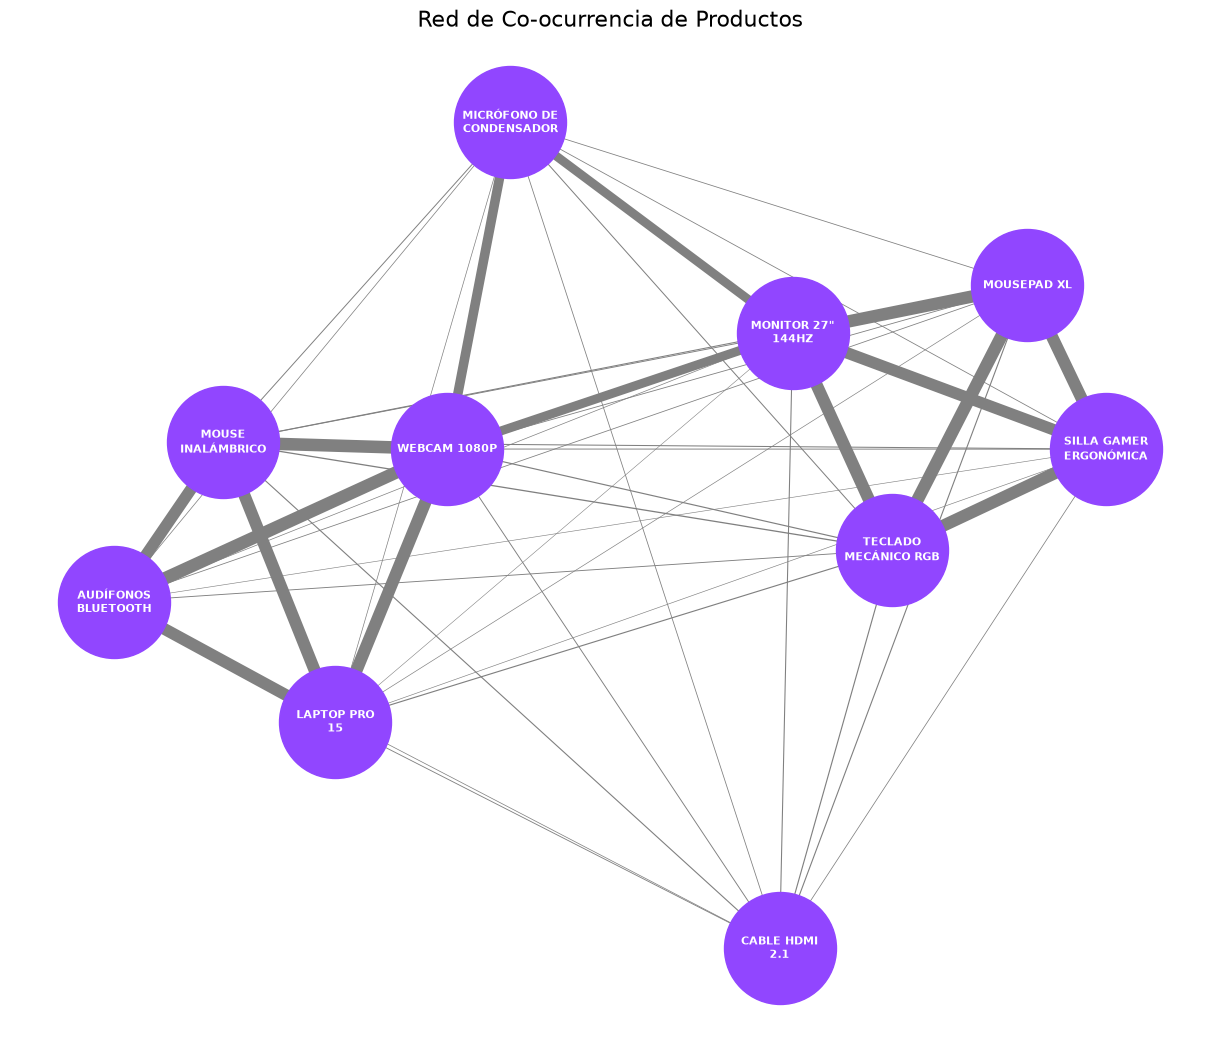

In [6]:
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42, weight='Peso')   # los pares fuertes se atraen
anchos = [d['Peso'] / 40 for (u, v, d) in G.edges(data=True)]
etiquetas = {n: '\n'.join(textwrap.wrap(n, 12)) for n in G.nodes()}

nx.draw(G, pos, labels=etiquetas, with_labels=True, node_color='#9146FF', node_size=6500,
        font_color='white', font_weight='bold', font_size=8, width=anchos, edge_color='gray')
plt.title('Red de Co-ocurrencia de Productos', fontsize=16)
plt.show()